# CA2, Phase 1: DCF and the slotted contention model

This notebook is **optional**: any language or tool is fine for the analysis (see the setup section of the assignment). It only **loads** simulation results; the model, the plots and the analysis are yours to write, in new cells under each section heading.

Rules:
- Your group's parameters come from `../params.json` (written by `ca2_params.py`). Do not type L or R by hand.
- Every number and plot in your report must be reproducible from the code you hand in; the TAs do not run it, but at the in-person delivery you will rerun parts of it and change them.

In [10]:
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from omnetpp.scave import results

with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)
L, R = P["L"], P["R"]
print(f"students: {', '.join(P['students'])}")
print(f"L = {L} B, R = {R} Mbps")

students: 810101469, 810102589
L = 900 B, R = 54 Mbps


## Loading results

`load_scalars(config)` returns every scalar of one config, with its iteration variables (for example `n` or `rtsThreshold`) and `repetition` as columns.
`scalar(sc, module, name)` returns one value per run: the scalar `name`, summed over all modules whose full path matches the regular expression `module`.

In [11]:
RESULTS = "results"


def load_scalars(config):
    df = results.read_result_files(os.path.join(RESULTS, f"{config}-*.sca"))
    sc = results.get_scalars(df, include_itervars=True, include_runattrs=True)
    for col in ("n", "repetition"):
        if col in sc:
            sc[col] = pd.to_numeric(sc[col])
    return sc


def scalar(sc, module, name):
    rows = sc[(sc.name == name) & sc.module.str.fullmatch(module)]
    keys = [c for c in ("n", "rtsThreshold", "repetition") if c in rows and rows[c].notna().all()]
    return rows.groupby(keys).value.sum()


def load_vector(config, module, name):
    df = results.read_result_files(os.path.join(RESULTS, f"{config}-*.vec"))
    v = results.get_vectors(df)
    row = v[(v.module == module) & (v.name == name)].iloc[0]
    return row.vectime, row.vecvalue

Example: frames received by the AP in each run of the `Hidden` config (run that config first).

In [12]:
hidden = load_scalars("Hidden")
scalar(hidden, r"Contention\.ap\.sink", "packets:count")

Series([], Name: value, dtype: float64)

## 1-1 A single exchange up close


In [13]:
import json
import os

# Load group parameters
with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)

L = P["L"]

# Parameters (seconds)
CW_min = 15
sigma = 9e-6
DIFS = 34e-6
SIFS = 16e-6
T_DATA = 160e-6
T_ACK = 28e-6

# Average number of backoff slots
k = CW_min / 2

# Backoff duration
T_backoff = k * sigma

# Total successful transmission cycle
T_cycle = DIFS + T_backoff + T_DATA + SIFS + T_ACK

# Analytical throughput
S1 = (8 * L) / T_cycle

print(f"L = {L} Bytes")
print(f"CW_min = {CW_min}")
print(f"Average backoff slots (k) = {k}")
print(f"Backoff duration = {T_backoff * 1e6:.2f} us")
print(f"Total cycle duration = {T_cycle * 1e6:.2f} us")
print(f"Analytical throughput S1 = {S1 / 1e6:.4f} Mbps")

L = 900 Bytes
CW_min = 15
Average backoff slots (k) = 7.5
Backoff duration = 67.50 us
Total cycle duration = 305.50 us
Analytical throughput S1 = 23.5679 Mbps


## 1-2  The slotted contention model

L = 900 Bytes
R = 54 Mbps
DATA transmission time = 160.00 us
tau_0 = 0.117647
T_s = 238.00 us
T_c = 194.00 us

S1 from section 1-3 = 23.5679 Mbps
S(1) from slotted model = 23.5679 Mbps
Maximum throughput = 25.2913 Mbps
Maximum throughput occurs at n = 2


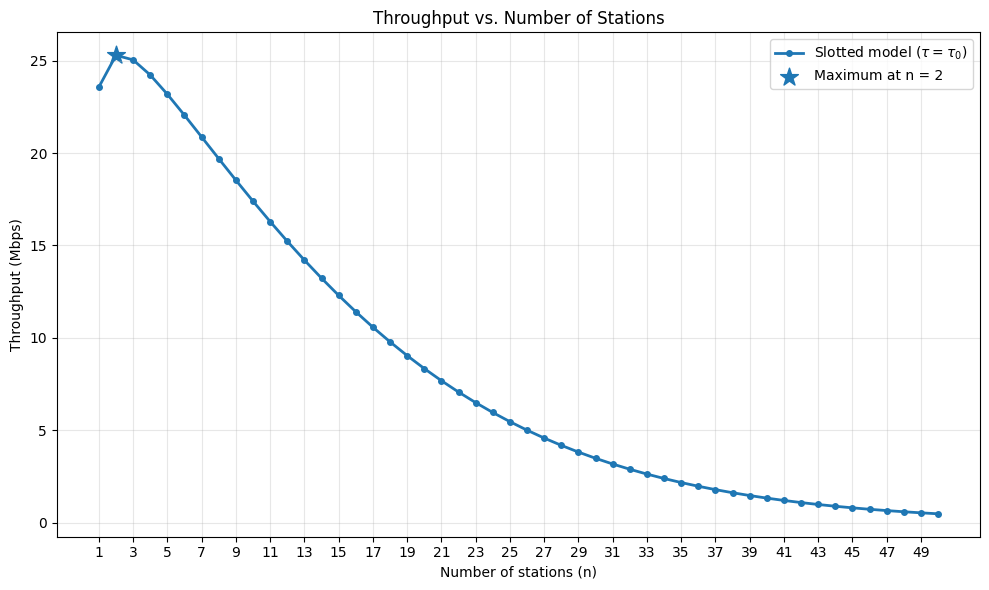

In [14]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt

# Load group parameters
with open(os.path.join("..", "params.json")) as f:
    P = json.load(f)

L = P["L"]
R = P["R"]

# MAC frame size includes the 31-byte protocol overhead
B = L + 31

# Calculate DATA transmission time using the 802.11a OFDM formula
N_DBPS = 4 * R
N_SYM = np.ceil((16 + 8 * B + 6) / N_DBPS)
T_DATA = 20e-6 + 4e-6 * N_SYM

# Define MAC timing parameters
CW_min = 15
sigma = 9e-6
DIFS = 34e-6
SIFS = 16e-6
T_ACK = 28e-6

# Calculate the fixed transmission probability
tau_0 = 2 / (CW_min + 2)

# Calculate successful and collision slot durations
T_s = DIFS + T_DATA + SIFS + T_ACK
T_c = DIFS + T_DATA

# Evaluate the model for 1 to 50 stations
n_values = np.arange(1, 51)

# Calculate the probability of each slot outcome
P_idle = (1 - tau_0) ** n_values
P_s = n_values * tau_0 * (1 - tau_0) ** (n_values - 1)
P_c = 1 - P_idle - P_s

# Calculate network throughput
S = (P_s * 8 * L) / (
    P_idle * sigma +
    P_s * T_s +
    P_c * T_c
)

# Convert throughput from bps to Mbps
S_Mbps = S / 1e6

# Calculate the single-station analytical throughput
k = CW_min / 2
S1 = (8 * L) / (
    DIFS + k * sigma + T_DATA + SIFS + T_ACK
)

# Verify that the model matches S1 when n = 1
assert np.isclose(S[0], S1, rtol=1e-10), (
    "The n=1 throughput does not match the analytical S1 value."
)

# Find the station count that gives maximum throughput
max_index = np.argmax(S_Mbps)
max_n = n_values[max_index]
max_S = S_Mbps[max_index]

# Print the calculated parameters and results
print(f"L = {L} Bytes")
print(f"R = {R} Mbps")
print(f"DATA transmission time = {T_DATA * 1e6:.2f} us")
print(f"tau_0 = {tau_0:.6f}")
print(f"T_s = {T_s * 1e6:.2f} us")
print(f"T_c = {T_c * 1e6:.2f} us")

print(f"\nS1 from section 1-3 = {S1 / 1e6:.4f} Mbps")
print(f"S(1) from slotted model = {S_Mbps[0]:.4f} Mbps")
print(f"Maximum throughput = {max_S:.4f} Mbps")
print(f"Maximum throughput occurs at n = {max_n}")

# Plot throughput versus the number of stations
plt.figure(figsize=(10, 6))

plt.plot(
    n_values,
    S_Mbps,
    marker="o",
    markersize=4,
    linewidth=2,
    label=r"Slotted model ($\tau = \tau_0$)"
)

plt.scatter(
    max_n,
    max_S,
    marker="*",
    s=180,
    label=f"Maximum at n = {max_n}"
)

plt.xlabel("Number of stations (n)")
plt.ylabel("Throughput (Mbps)")
plt.title("Throughput vs. Number of Stations")
plt.xticks(np.arange(1, 51, 2))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 1-3  Model versus simulator

Number of runs: 50

Per-run results:


,n,repetition,N_first,N_retry,N_drop,N_rx,p_hat,tau_hat,S_sim_Mbps
0,1,0,32713.0,0.0,0.0,32713.0,0.00000,NaN,23.55336
1,1,1,32726.0,0.0,0.0,32726.0,0.00000,NaN,23.56272
2,1,2,32737.0,0.0,0.0,32737.0,0.00000,NaN,23.57064
3,1,3,32694.0,0.0,0.0,32694.0,0.00000,NaN,23.53968
4,1,4,32673.0,0.0,0.0,32673.0,0.00000,NaN,23.52456
5,2,0,33817.0,4108.0,0.0,33815.0,0.10832,0.10832,24.34680
6,2,1,33815.0,4102.0,0.0,33815.0,0.10818,0.10818,24.34680
7,2,2,33779.0,4190.0,0.0,33777.0,0.11035,0.11035,24.31944
8,2,3,33703.0,4279.0,0.0,33704.0,0.11266,0.11266,24.26688
9,2,4,33775.0,4178.0,0.0,33775.0,0.11008,0.11008,24.31800



Summary for each number of stations:


,n,repetitions,S_mean,CI_lower,CI_upper,p_hat_pooled,tau_hat_pooled,tau_hat_mean
0,1,5,23.55019,23.52736,23.57302,0.00000,NaN,NaN
1,2,5,24.31958,24.27906,24.36011,0.10992,0.10992,0.10992
2,3,5,24.08126,24.04945,24.11308,0.17777,0.09323,0.09323
3,5,5,23.29402,23.25903,23.32900,0.26218,0.07320,0.07320
4,8,5,22.30949,22.24547,22.37350,0.33666,0.05695,0.05695
5,10,5,21.78850,21.72691,21.85008,0.36933,0.04993,0.04993
6,15,5,20.77445,20.70910,20.83979,0.42945,0.03929,0.03929
7,20,5,20.02550,19.97544,20.07557,0.47049,0.03291,0.03291
8,25,5,19.37837,19.30809,19.44864,0.50283,0.02870,0.02870
9,30,5,18.86731,18.82653,18.90810,0.52743,0.02552,0.02552


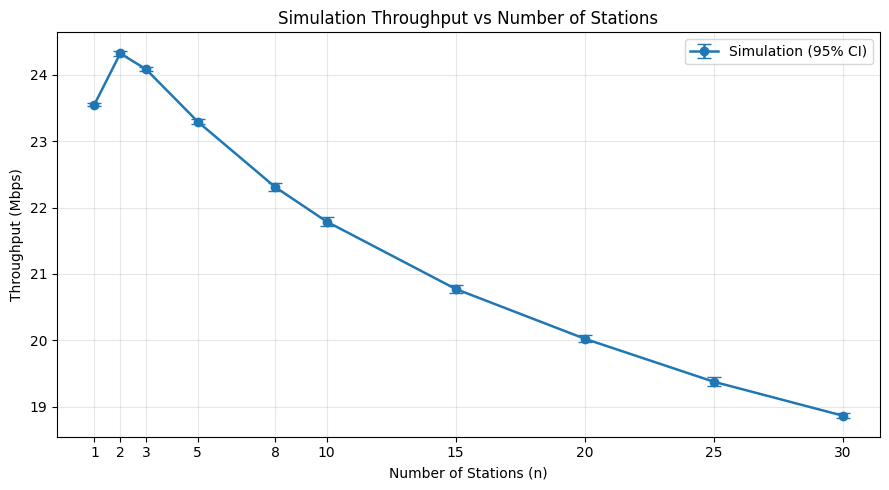

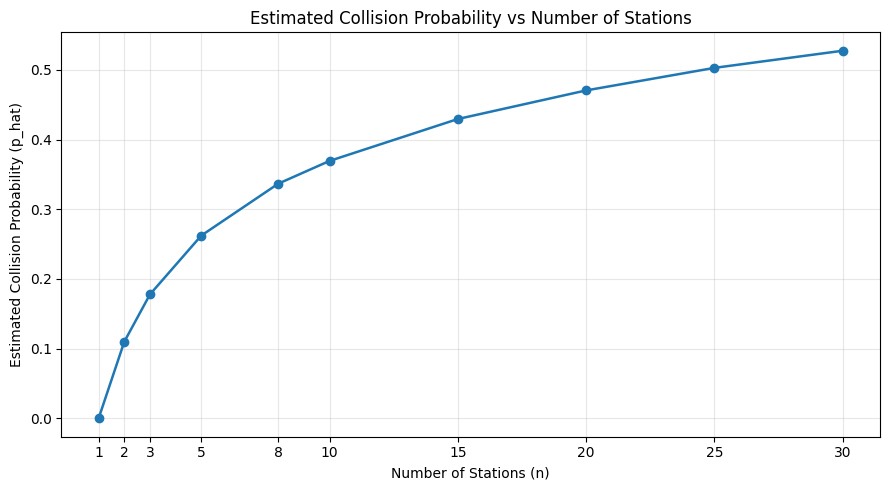

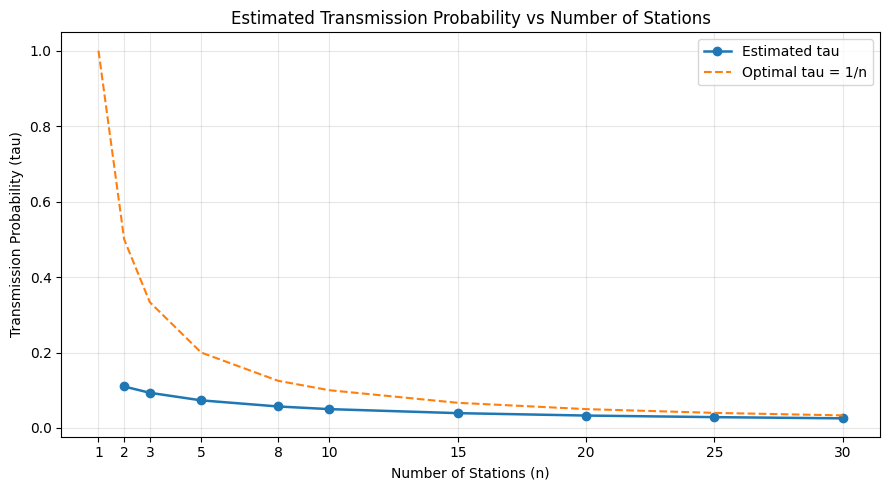

In [15]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Load Sweep results
# --------------------------------------------------

sweep_data = load_scalars("Sweep")

# --------------------------------------------------
# 2. Extract MAC statistics
# Sum values across all stations for each run
# --------------------------------------------------

N_first = scalar(
    sweep_data,
    r"Contention\.host\[.*\]\.wlan\.mac\.dcf",
    "packetSentToPeerWithoutRetry:count"
)

N_retry = scalar(
    sweep_data,
    r"Contention\.host\[.*\]\.wlan\.mac\.dcf",
    "packetSentToPeerWithRetry:count"
)

N_drop = scalar(
    sweep_data,
    r"Contention\.host\[.*\]\.wlan\.mac\.dcf",
    "packetDropRetryLimitReached:count"
)

df_mac = pd.concat(
    [N_first, N_retry, N_drop],
    axis=1,
    keys=["N_first", "N_retry", "N_drop"]
).reset_index()

df_mac = df_mac.fillna(0)

# --------------------------------------------------
# 3. Extract packets received at the AP
# --------------------------------------------------

N_rx = scalar(
    sweep_data,
    r"Contention\.ap\.sink",
    "packets:count"
)

df_rx = (
    N_rx.reset_index()
    .rename(columns={"value": "N_rx"})
)

# --------------------------------------------------
# 4. Merge data using n and repetition
# --------------------------------------------------

df = pd.merge(
    df_mac,
    df_rx,
    on=["n", "repetition"],
    how="inner",
    validate="one_to_one"
)

df = df.sort_values(["n", "repetition"]).reset_index(drop=True)

# Convert counters to numeric values
counter_cols = ["N_first", "N_retry", "N_drop", "N_rx"]

df[counter_cols] = df[counter_cols].apply(
    pd.to_numeric,
    errors="coerce"
).fillna(0)

# --------------------------------------------------
# 5. Estimate collision probability per run
# --------------------------------------------------

denominator = df["N_first"] + df["N_retry"]

df["p_hat"] = np.where(
    denominator > 0,
    (df["N_retry"] + df["N_drop"]) / denominator,
    np.nan
)

# --------------------------------------------------
# 6. Estimate actual transmission probability
# --------------------------------------------------

df["tau_hat"] = np.nan

valid_n = (df["n"] > 1) & df["p_hat"].notna()

df.loc[valid_n, "tau_hat"] = (
    1 - (1 - df.loc[valid_n, "p_hat"])
    ** (1 / (df.loc[valid_n, "n"] - 1))
)

# --------------------------------------------------
# 7. Calculate simulation throughput
# --------------------------------------------------

T = 10.0  # 12s simulation - 2s warmup

L_bits = L * 8

df["S_sim_Mbps"] = (
    df["N_rx"] * L_bits / T / 1e6
)

# --------------------------------------------------
# 8. Aggregate results for each n
# --------------------------------------------------

summary = df.groupby("n").agg(
    repetitions=("repetition", "nunique"),
    S_mean=("S_sim_Mbps", "mean"),
    S_std=("S_sim_Mbps", "std"),
    p_hat_mean=("p_hat", "mean"),
    tau_hat_mean=("tau_hat", "mean"),
    N_first_total=("N_first", "sum"),
    N_retry_total=("N_retry", "sum"),
    N_drop_total=("N_drop", "sum")
).reset_index()

# Pooled collision probability across all repetitions
pooled_denominator = (
    summary["N_first_total"] + summary["N_retry_total"]
)

summary["p_hat_pooled"] = np.where(
    pooled_denominator > 0,
    (
        summary["N_retry_total"] + summary["N_drop_total"]
    ) / pooled_denominator,
    np.nan
)

# Transmission probability based on pooled collision probability
summary["tau_hat_pooled"] = np.nan

valid_n = (
    (summary["n"] > 1)
    & summary["p_hat_pooled"].notna()
)

summary.loc[valid_n, "tau_hat_pooled"] = (
    1 - (1 - summary.loc[valid_n, "p_hat_pooled"])
    ** (1 / (summary.loc[valid_n, "n"] - 1))
)

# --------------------------------------------------
# 9. Calculate 95% confidence interval for throughput
# --------------------------------------------------

T_CRITICAL = 2.776445  # 95% CI, 4 degrees of freedom

summary["CI_margin"] = (
    T_CRITICAL
    * summary["S_std"]
    / np.sqrt(summary["repetitions"])
)

summary["CI_lower"] = summary["S_mean"] - summary["CI_margin"]
summary["CI_upper"] = summary["S_mean"] + summary["CI_margin"]

# --------------------------------------------------
# 10. Display results
# --------------------------------------------------

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 5)

print("Number of runs:", len(df))
print("\nPer-run results:")
display(df)

print("\nSummary for each number of stations:")
display(
    summary[
        [
            "n",
            "repetitions",
            "S_mean",
            "CI_lower",
            "CI_upper",
            "p_hat_pooled",
            "tau_hat_pooled",
            "tau_hat_mean"
        ]
    ]
)

# ==========================================
# Plot simulation results
# ==========================================

# 1. Throughput vs Number of Stations
plt.figure(figsize=(9, 5))

plt.errorbar(
    summary['n'],
    summary['S_mean'],
    yerr=[
        summary['S_mean'] - summary['CI_lower'],
        summary['CI_upper'] - summary['S_mean']
    ],
    fmt='o-',
    capsize=5,
    linewidth=1.8,
    markersize=6,
    label='Simulation (95% CI)'
)

plt.xlabel('Number of Stations (n)')
plt.ylabel('Throughput (Mbps)')
plt.title('Simulation Throughput vs Number of Stations')
plt.xticks(summary['n'])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# 2. Estimated Collision Probability vs Number of Stations
plt.figure(figsize=(9, 5))

plt.plot(
    summary['n'],
    summary['p_hat_pooled'],
    'o-',
    linewidth=1.8,
    markersize=6
)

plt.xlabel('Number of Stations (n)')
plt.ylabel('Estimated Collision Probability (p_hat)')
plt.title('Estimated Collision Probability vs Number of Stations')
plt.xticks(summary['n'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Estimated Transmission Probability vs Number of Stations
plt.figure(figsize=(9, 5))

plt.plot(
    summary['n'],
    summary['tau_hat_pooled'],
    'o-',
    linewidth=1.8,
    markersize=6,
    label='Estimated tau'
)

plt.plot(
    summary['n'],
    1 / summary['n'],
    '--',
    linewidth=1.5,
    label='Optimal tau = 1/n'
)

plt.xlabel('Number of Stations (n)')
plt.ylabel('Transmission Probability (tau)')
plt.title('Estimated Transmission Probability vs Number of Stations')
plt.xticks(summary['n'])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

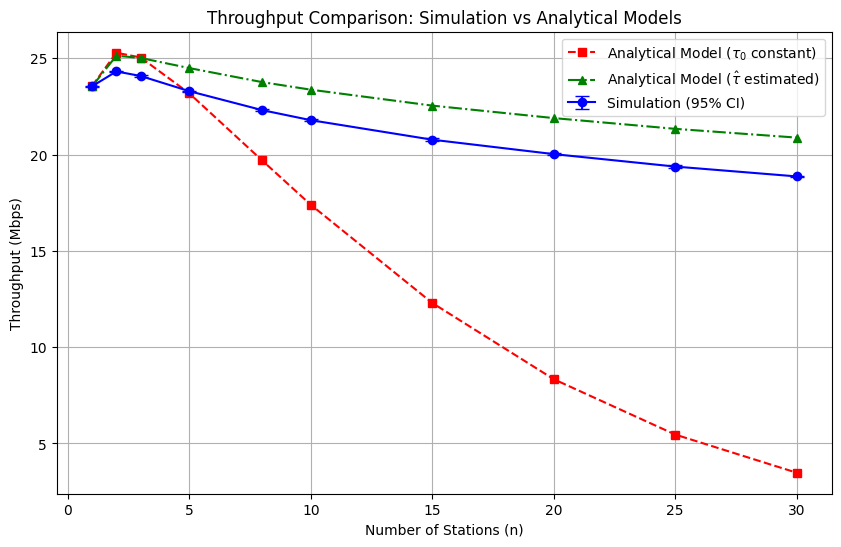

Comparison of tau_0, 1/n, and tau_hat:
n	tau_0		1/n		tau_hat
2	0.11765		0.50000		0.10992
3	0.11765		0.33333		0.09323
5	0.11765		0.20000		0.07320
8	0.11765		0.12500		0.05695
10	0.11765		0.10000		0.04993
15	0.11765		0.06667		0.03929
20	0.11765		0.05000		0.03291
25	0.11765		0.04000		0.02870
30	0.11765		0.03333		0.02552

--- Metrics at n=30 ---
Simulated S: 18.867 Mbps
Model (tau_0) S: 3.478 Mbps | Relative Error: 81.6%
Model (tau_hat) S: 20.883 Mbps | Relative Error: 10.7%
Overestimation by tau_hat model: 2.016 Mbps


In [16]:
import scipy.stats as st

n_sim = mean_results['n'].values
S_sim = mean_results['S_sim_Mbps'].values
tau_hat_vals = mean_results['tau_hat'].values

ci_lower = []
ci_upper = []
for n_val in n_sim:
    data = df[df['n'] == n_val]['S_sim_Mbps']
    if len(data) > 1:
        ci = st.t.interval(0.95, df=len(data)-1, loc=np.mean(data), scale=st.sem(data))
        ci_lower.append(ci[0])
        ci_upper.append(ci[1])
    else:
        ci_lower.append(np.mean(data))
        ci_upper.append(np.mean(data))

yerr = [S_sim - np.array(ci_lower), np.array(ci_upper) - S_sim]

tau_0 = 2 / (CW_min + 2)
P_idle_0 = (1 - tau_0)**n_sim
P_s_0 = n_sim * tau_0 * (1 - tau_0)**(n_sim - 1)
P_c_0 = 1 - P_idle_0 - P_s_0
S_tau0 = (P_s_0 * 8 * L) / (P_idle_0 * sigma + P_s_0 * T_s + P_c_0 * T_c) / 1e6

S_tau_hat = np.zeros_like(S_sim)
for i, n_val in enumerate(n_sim):
    if n_val == 1:
        S_tau_hat[i] = S_sim[i] 
    else:
        t_hat = tau_hat_vals[i]
        P_idle_hat = (1 - t_hat)**n_val
        P_s_hat = n_val * t_hat * (1 - t_hat)**(n_val - 1)
        P_c_hat = 1 - P_idle_hat - P_s_hat
        S_tau_hat[i] = (P_s_hat * 8 * L) / (P_idle_hat * sigma + P_s_hat * T_s + P_c_hat * T_c) / 1e6

plt.figure(figsize=(10, 6))
plt.errorbar(n_sim, S_sim, yerr=yerr, fmt='-o', capsize=5, label='Simulation (95% CI)', color='blue')
plt.plot(n_sim, S_tau0, '--s', label=r'Analytical Model ($\tau_0$ constant)', color='red')
plt.plot(n_sim, S_tau_hat, '-.^', label=r'Analytical Model ($\hat{\tau}$ estimated)', color='green')
plt.xlabel('Number of Stations (n)')
plt.ylabel('Throughput (Mbps)')
plt.title('Throughput Comparison: Simulation vs Analytical Models')
plt.grid(True)
plt.legend()
plt.show()

print("Comparison of tau_0, 1/n, and tau_hat:")
print("n\ttau_0\t\t1/n\t\ttau_hat")
for i, n_val in enumerate(n_sim):
    if n_val > 1:
        print(f"{n_val}\t{tau_0:.5f}\t\t{1/n_val:.5f}\t\t{tau_hat_vals[i]:.5f}")

idx_30 = np.where(n_sim == 30)[0][0]
err_tau0 = abs(S_tau0[idx_30] - S_sim[idx_30]) / S_sim[idx_30] * 100
err_tau_hat = abs(S_tau_hat[idx_30] - S_sim[idx_30]) / S_sim[idx_30] * 100

print(f"\n--- Metrics at n=30 ---")
print(f"Simulated S: {S_sim[idx_30]:.3f} Mbps")
print(f"Model (tau_0) S: {S_tau0[idx_30]:.3f} Mbps | Relative Error: {err_tau0:.1f}%")
print(f"Model (tau_hat) S: {S_tau_hat[idx_30]:.3f} Mbps | Relative Error: {err_tau_hat:.1f}%")
print(f"Overestimation by tau_hat model: {S_tau_hat[idx_30] - S_sim[idx_30]:.3f} Mbps")

## 1-4  Hidden terminal and RTS/CTS